Yuliia Chernysheva  
October 16, 2026  
CIS 2267 Midterm Project: US Farmland Data Analysis (2012 vs 2017)  

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Set standard plotting aesthetics for Seaborn
sns.set_theme(style="whitegrid")

# PART 1: Loading, Cleaning, and Analyzing Farmland Census Data

In [2]:
# 1. Load the initial dataset from CSV into a DataFrame
df_farmland = pd.read_csv("Farmland.csv")

# Display initial rows and dataset summary
print("=> Initial five rows of the Farmland dataset:\n")
display(df_farmland.head())

print("\n=> Dataset Structure and Info:\n")
display(df_farmland.info())

=> Initial five rows of the Farmland dataset:



,State,2012Farmland,2017Farmland
0,Alabama,"8,902,654","8,580,940"
1,Alaska,"833,861","849,753"
2,Arizona,"26,249,195","26,125,819"
3,Arkansas,"13,810,786","13,888,929"
4,California,"25,569,001","24,522,801"



=> Dataset Structure and Info:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   State         50 non-null     object
 1   2012Farmland  50 non-null     object
 2   2017Farmland  50 non-null     object
dtypes: object(3)
memory usage: 1.3+ KB


None

In [3]:
# 2. Rename columns to standard snake_case for consistency
df_farmland = df_farmland.rename(columns={
    'State':'state',
    '2012Farmland':'farmland_2012',
    '2017Farmland':'farmland_2017'
})

# Normalize state names to Title Case (handles 'OHIO' -> 'Ohio')
df_farmland.state = df_farmland.state.str.title()

# Clean string formatting (remove commas/spaces) and convert to integer values
for col in ['farmland_2012', 'farmland_2017']:
    if df_farmland[col].dtype == 'object':
        df_farmland[col] = (
            df_farmland[col]
                .astype(str)
                .str.replace(',','', regex=False)
                .str.strip()
                .astype(int)
        )   

# 3. Calculate Absolute Difference (Net Change in Acres) and Relative Difference (% Change)
df_farmland['diff_abs'] = (df_farmland.farmland_2017 - df_farmland.farmland_2012)
df_farmland['diff_pct'] = ((df_farmland.diff_abs/df_farmland.farmland_2012) * 100) 

# 4. Sort Rankings
print("=> Top States by Absolute Farmland Change (Highest Gain to Largest Loss):\n")
df_farmland.sort_values(
    by='diff_abs',
    ascending=False
).assign(
    farmland_2012=lambda df: df['farmland_2012'].map('{:,.0f}'.format),
    farmland_2017=lambda df: df['farmland_2017'].map('{:,.0f}'.format),
    diff_abs=lambda df: df['diff_abs'].map('{:+,.0f}'.format),
    diff_pct=lambda df: df['diff_pct'].map('{:+.2f}%'.format)
)

=> Top States by Absolute Farmland Change (Highest Gain to Largest Loss):



,state,farmland_2012,farmland_2017,diff_abs,diff_pct
9,Georgia,"9,620,836","9,953,730","+332,894",+3.46%
13,Indiana,"14,720,396","14,969,996","+249,600",+1.70%
27,Nevada,"5,913,761","6,128,153","+214,392",+3.63%
8,Florida,"9,548,342","9,731,731","+183,389",+1.92%
17,Louisiana,"7,900,864","7,997,511","+96,647",+1.22%
33,North Dakota,"39,262,613","39,341,591","+78,978",+0.20%
3,Arkansas,"13,810,786","13,888,929","+78,143",+0.57%
12,Illinois,"26,937,721","27,006,288","+68,567",+0.25%
47,West Virginia,"3,606,674","3,662,178","+55,504",+1.54%
29,New Jersey,"715,057","734,084","+19,027",+2.66%


In [4]:
print("=> Top States by Percentage Farmland Change (Highest Gain to Largest Loss):\n")
df_farmland.sort_values(
    by='diff_pct',
    ascending=False
).assign(
    farmland_2012=lambda df: df['farmland_2012'].map('{:,.0f}'.format),
    farmland_2017=lambda df: df['farmland_2017'].map('{:,.0f}'.format),
    diff_abs=lambda df: df['diff_abs'].map('{:+,.0f}'.format),
    diff_pct=lambda df: df['diff_pct'].map('{:+.2f}%'.format)
)

=> Top States by Percentage Farmland Change (Highest Gain to Largest Loss):



,state,farmland_2012,farmland_2017,diff_abs,diff_pct
27,Nevada,"5,913,761","6,128,153","+214,392",+3.63%
9,Georgia,"9,620,836","9,953,730","+332,894",+3.46%
7,Delaware,"508,652","525,324","+16,672",+3.28%
29,New Jersey,"715,057","734,084","+19,027",+2.66%
8,Florida,"9,548,342","9,731,731","+183,389",+1.92%
1,Alaska,"833,861","849,753","+15,892",+1.91%
13,Indiana,"14,720,396","14,969,996","+249,600",+1.70%
47,West Virginia,"3,606,674","3,662,178","+55,504",+1.54%
17,Louisiana,"7,900,864","7,997,511","+96,647",+1.22%
3,Arkansas,"13,810,786","13,888,929","+78,143",+0.57%


In [5]:
# 5. Descriptive Statistics for Numerical Columns
numeric_cols = ['farmland_2012','farmland_2017','diff_abs','diff_pct']
summary_stats = df_farmland[numeric_cols].agg(['sum', 'mean', 'min', 'max'])

print("\n=> Summary Statistics (Sum, Mean, Min, Max):")
display(summary_stats.assign(
    farmland_2012=lambda df: df['farmland_2012'].map('{:,.0f}'.format),
    farmland_2017=lambda df: df['farmland_2017'].map('{:,.0f}'.format),
    diff_abs=lambda df: df['diff_abs'].map('{:+,.0f}'.format),
    diff_pct=lambda df: df['diff_pct'].map('{:+.2f}%'.format)
))

# The true national percentage change 
total_2012 = df_farmland['farmland_2012'].sum()
total_2017 = df_farmland['farmland_2017'].sum()
national_pct_change = ((total_2017 - total_2012) / total_2012) * 100

print(f"\n=> True Overall National Farmland Change (2012-2017): {national_pct_change:.2f}%")


=> Summary Statistics (Sum, Mean, Min, Max):


,farmland_2012,farmland_2017,diff_abs,diff_pct
sum,"914,527,657","900,217,576","-14,310,081",-104.93%
mean,"18,290,553","18,004,352","-286,202",-2.10%
min,"69,589","56,864","-3,117,254",-18.29%
max,"130,153,438","127,036,184","+332,894",+3.63%



=> True Overall National Farmland Change (2012-2017): -1.56%


_Note on Statistical Aggregation:_

* `Sum of percentages (-104.93%):` Summing percentage changes across states is mathematically invalid because each percentage represents a change relative to a different state base.
  
* `State Mean (-2.10%):` The average percentage change across all 50 states treats every state equally regardless of physical size.

* `True National Change (-1.56%):` The actual national loss of agricultural land (-14.31 million acres) calculated directly from total 2012 and 2017 farmland totals.

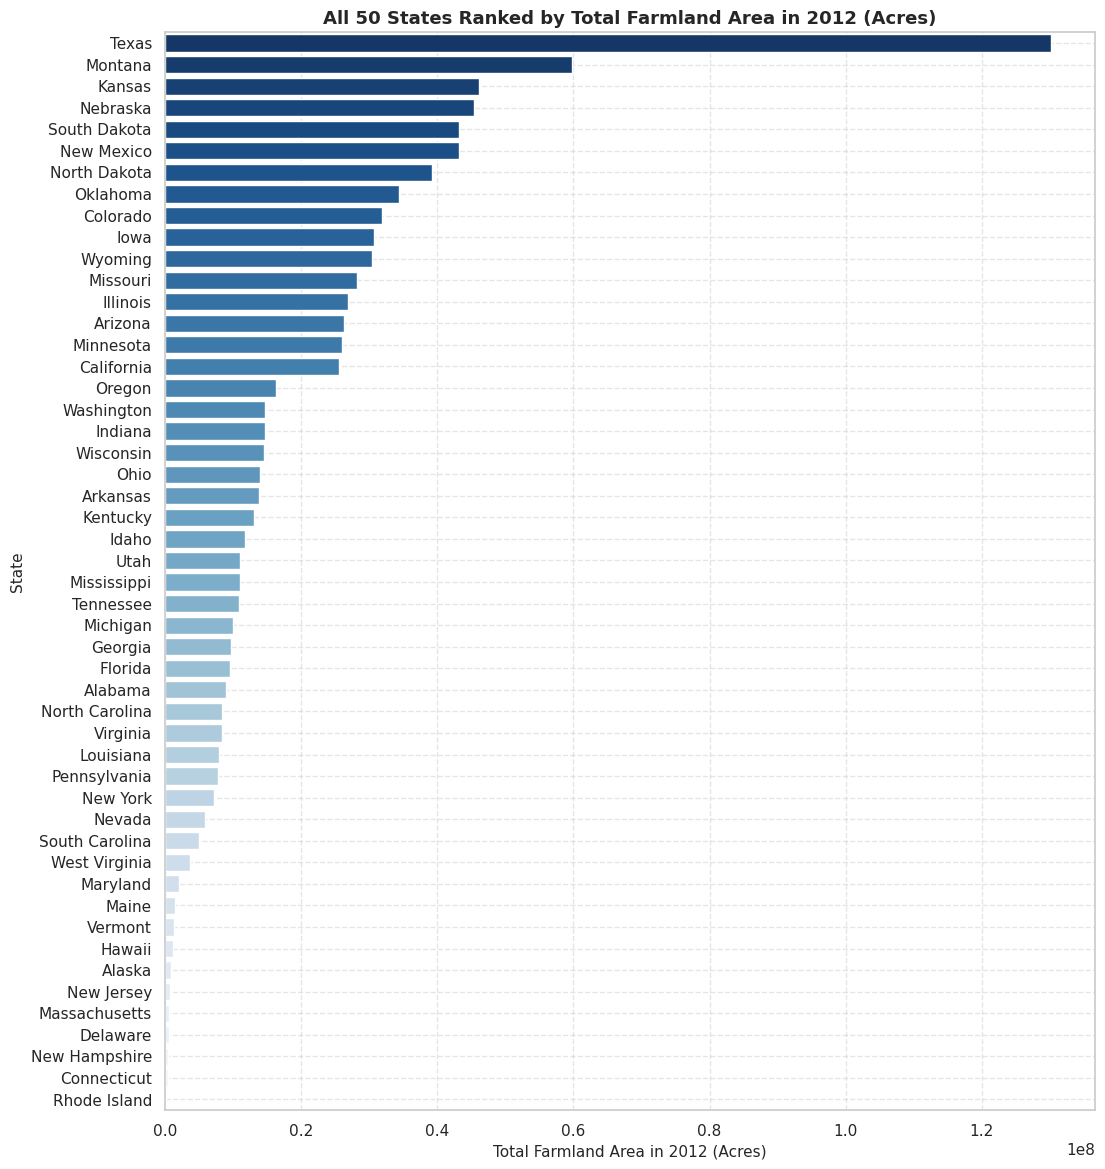

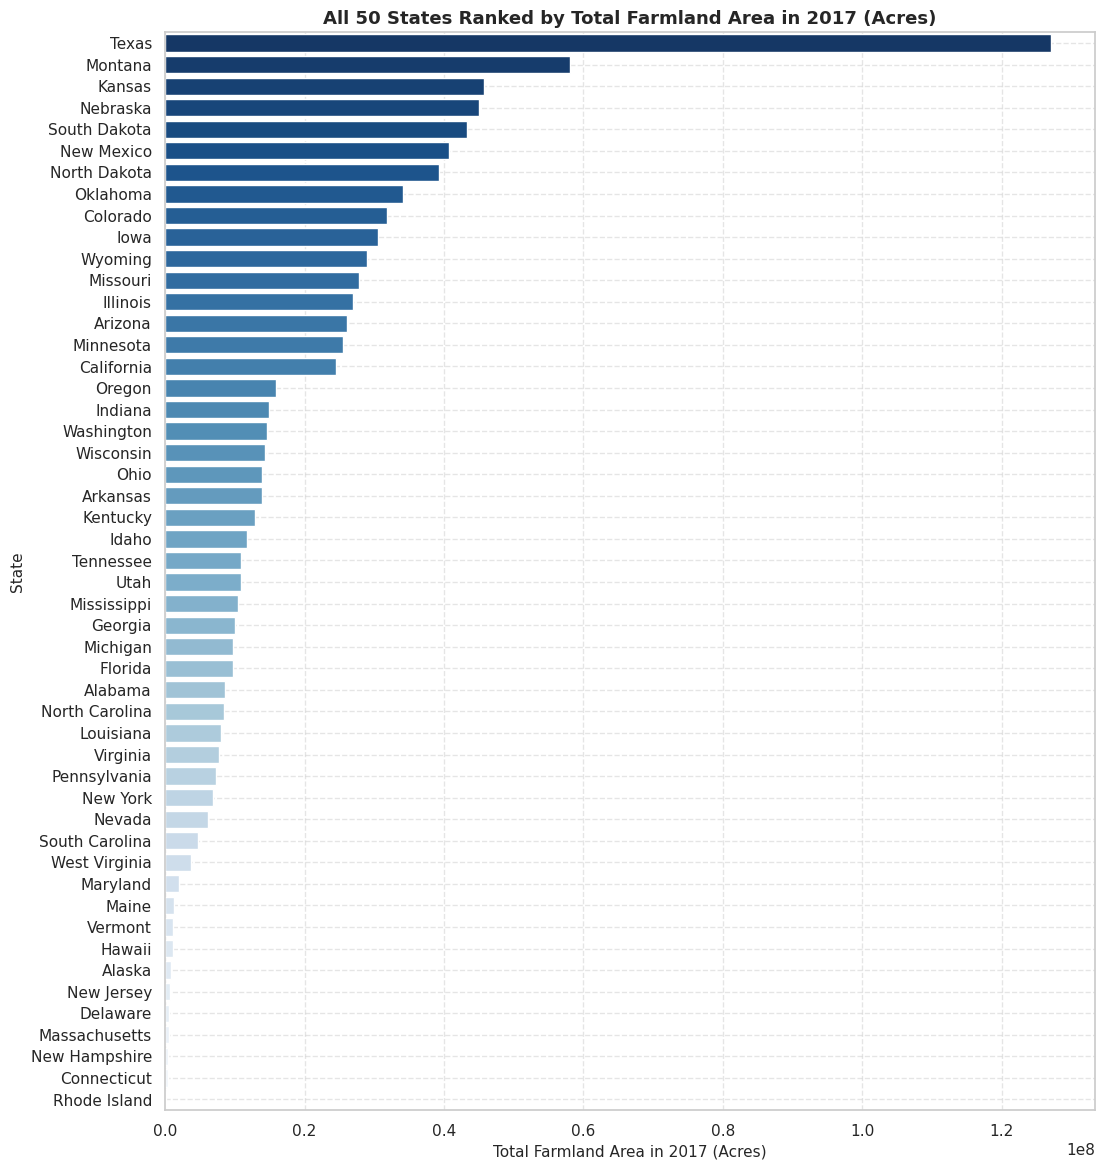

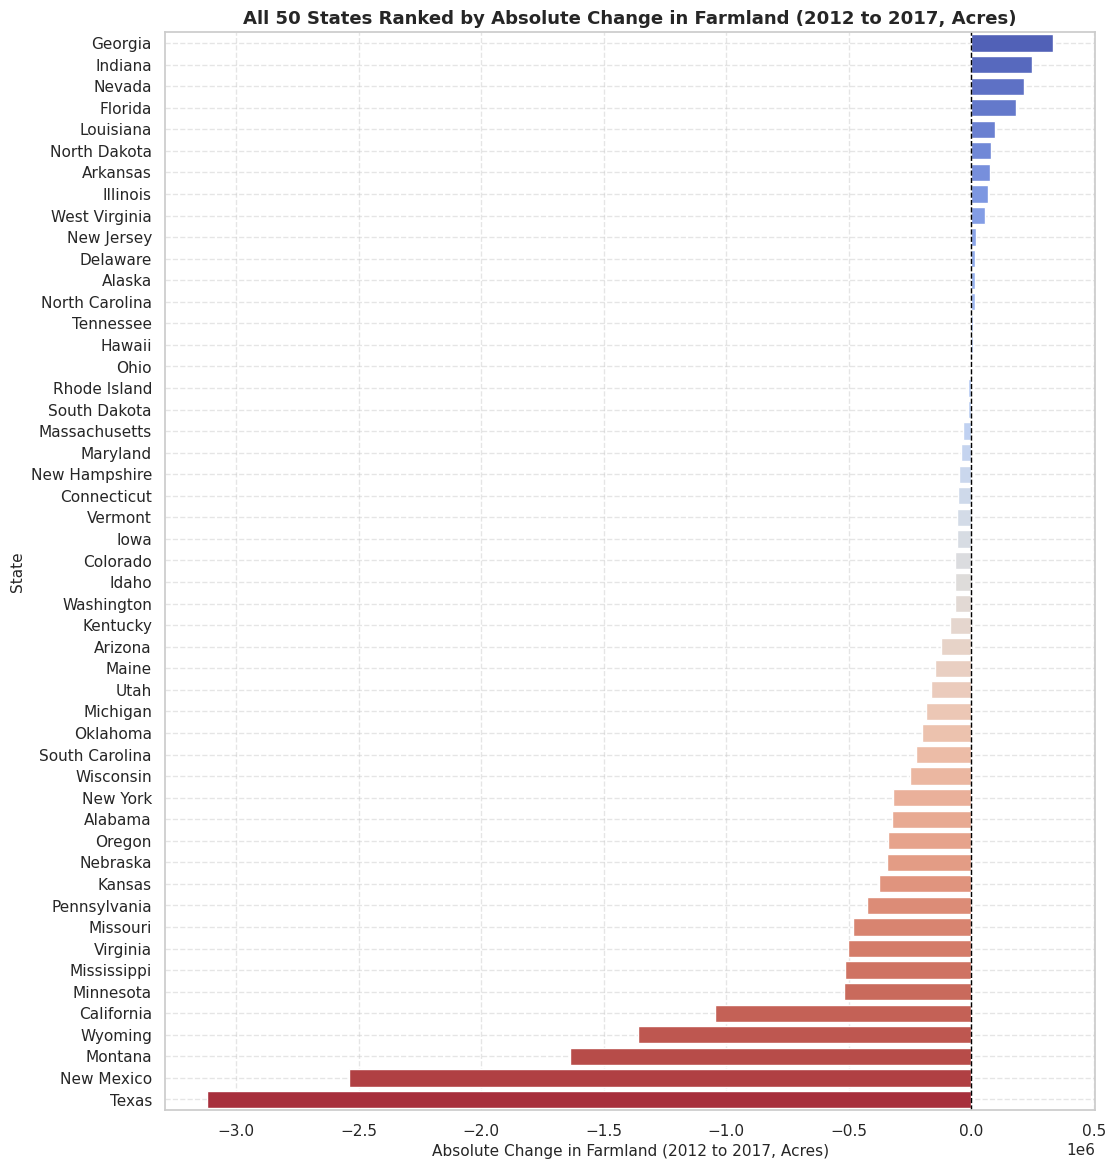

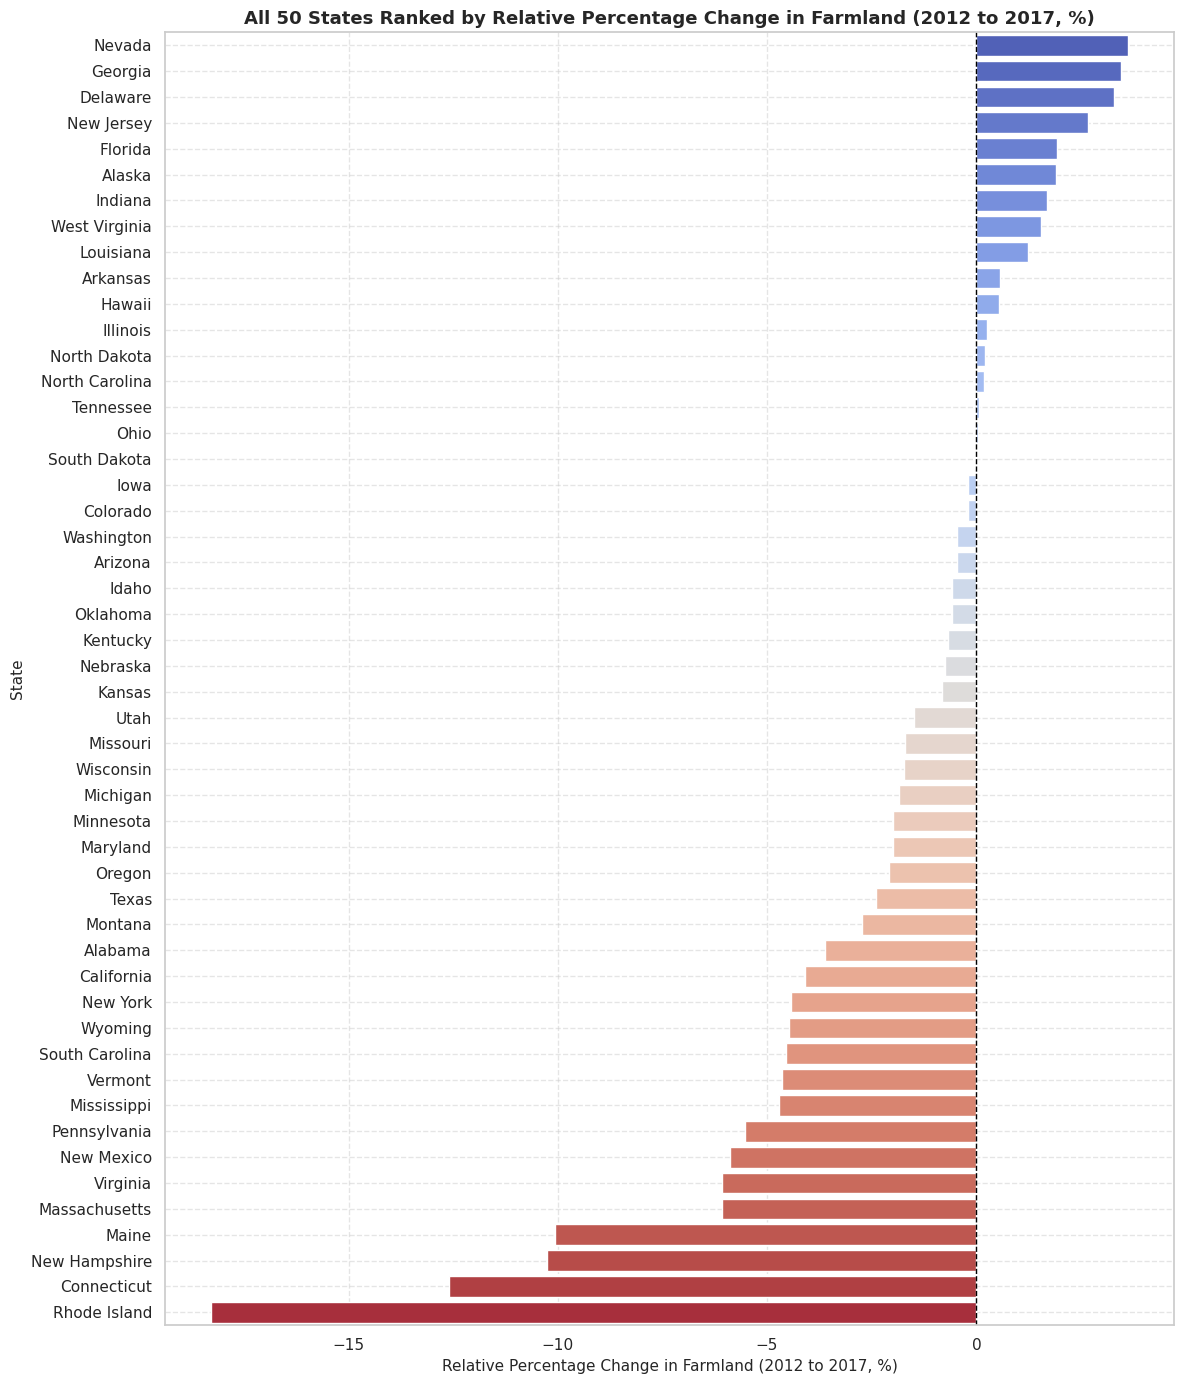

In [6]:
# 6. Visualization: Four Horizontal Bar Charts
titles_dict = {
    'farmland_2012': 'Total Farmland Area in 2012 (Acres)',
    'farmland_2017': 'Total Farmland Area in 2017 (Acres)',
    'diff_abs': 'Absolute Change in Farmland (2012 to 2017, Acres)',
    'diff_pct': 'Relative Percentage Change in Farmland (2012 to 2017, %)'
}

for col in numeric_cols:
    plt.figure(figsize=(12,14))
    
    # Sort dataset descending for each metric
    sorted_df  = df_farmland[[col,'state']].sort_values(by=col, ascending=False)

    # Plot horizontal bars
    sns.barplot(
        data=sorted_df, 
        x=col, 
        y='state',          
        palette='Blues_r' if 'diff' not in col else 'coolwarm',        
        hue='state',
        legend=False)

    # Add vertical zero line for change metrics to clearly separate gains and losses
    if 'diff' in col:
        plt.axvline(0, color='black', linewidth=1, linestyle='--')
        
    plt.title(f"All 50 States Ranked by {titles_dict[col]}", fontsize=13, fontweight='bold')
    plt.xlabel(titles_dict[col], fontsize=11)
    plt.ylabel('State', fontsize=11)        
    plt.grid(True, which="major", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# PART 2: Merging State Landmass Data & Evaluating Agricultural Density

In [7]:
# 1. Load U.S. Census Gazetteer File containing official land area data
df_state_area = pd.read_csv("2026_Gaz_state_national.csv")

# Clean column headers
df_state_area.columns = df_state_area.columns.str.strip().str.upper()

# Convert Land Area from Square Miles to Acres (1 Square Mile = 640 Acres)
df_state_area['ALAND_ACRES'] = df_state_area['ALAND_SQMI'] * 640

# Select and rename relevant columns for merging
df_state_area = df_state_area[['NAME','ALAND_ACRES']]
df_state_area.columns = df_state_area.columns.str.lower()

missing_in_gazetteer = set(df_farmland.state) - set(df_state_area.name)
if missing_in_gazetteer:
    print(f"Attention! The following states were not found in the Gazetteer: {missing_in_gazetteer}")

# 2. Merge Farmland dataset with State Landmass dataset
merged_df = pd.merge(df_farmland, 
                     df_state_area, 
                     left_on='state', 
                     right_on='name', 
                     how='left'
                    ).drop('name', axis=1)

# 3. Calculate metrics relative to state and national landmass
# Farmland as % of total state landmass
merged_df['pct_landmass_2012'] = ((merged_df.farmland_2012 / merged_df.aland_acres) * 100)
merged_df['pct_landmass_2017'] = ((merged_df.farmland_2017 / merged_df.aland_acres) * 100)

# State landmass as % of total U.S. 50-state landmass
total_us_landmass = merged_df.aland_acres.sum()
merged_df['pct_us_aland'] = ((merged_df.aland_acres / total_us_landmass) * 100)

# 4. Display results sorted by highest proportion of state land dedicated to farming (2017)
print("=> Merged Dataset Ranked by Farmland Share of State Area (2017):\n")
merged_df_sorted = merged_df.sort_values(by='pct_landmass_2017', ascending=False)

display(merged_df_sorted.assign(    
    farmland_2012=lambda df: df['farmland_2012'].map('{:,.0f}'.format),
    farmland_2017=lambda df: df['farmland_2017'].map('{:,.0f}'.format),
    aland_acres=lambda df: df['aland_acres'].map('{:,.0f}'.format),
    diff_abs=lambda df: df['diff_abs'].map('{:+,.0f}'.format),
    diff_pct=lambda df: df['diff_pct'].map('{:+.2f}%'.format),
    pct_landmass_2012=lambda df: df['pct_landmass_2012'].map('{:+.2f}%'.format),
    pct_landmass_2017=lambda df: df['pct_landmass_2017'].map('{:+.2f}%'.format),
    pct_us_aland=lambda df: df['pct_us_aland'].map('{:+.2f}%'.format)
))

=> Merged Dataset Ranked by Farmland Share of State Area (2017):



,state,farmland_2012,farmland_2017,diff_abs,diff_pct,aland_acres,pct_landmass_2012,pct_landmass_2017,pct_us_aland
26,Nebraska,"45,331,783","44,986,821","-344,962",-0.76%,"49,161,798",+92.21%,+91.51%,+2.17%
40,South Dakota,"43,257,079","43,243,742","-13,337",-0.03%,"48,517,944",+89.16%,+89.13%,+2.15%
33,North Dakota,"39,262,613","39,341,591","+78,978",+0.20%,"44,156,348",+88.92%,+89.10%,+1.95%
15,Kansas,"46,137,295","45,759,319","-377,976",-0.82%,"52,325,627",+88.17%,+87.45%,+2.31%
14,Iowa,"30,622,731","30,563,878","-58,853",-0.19%,"35,746,383",+85.67%,+85.50%,+1.58%
35,Oklahoma,"34,356,110","34,156,290","-199,820",-0.58%,"43,901,827",+78.26%,+77.80%,+1.94%
12,Illinois,"26,937,721","27,006,288","+68,567",+0.25%,"35,528,663",+75.82%,+76.01%,+1.57%
42,Texas,"130,153,438","127,036,184","-3,117,254",-2.40%,"167,206,078",+77.84%,+75.98%,+7.39%
13,Indiana,"14,720,396","14,969,996","+249,600",+1.70%,"22,928,117",+64.20%,+65.29%,+1.01%
24,Missouri,"28,266,137","27,781,883","-484,254",-1.71%,"43,997,781",+64.24%,+63.14%,+1.95%


# Part 3: Data Analysis & Policy Synthesis Report

## Data Accuracy, Research, and Methodological Considerations

Careful data checking is important in data analysis to make sure the results are accurate, reliable, and fair. For this study, the main data comes from the USDA Census of Agriculture and the American Farmland Trust (AFT). Several important factors must be considered:

* **Data Sources and Accuracy:** The main farmland data comes from the USDA National Agricultural Statistics Service (NASS). The USDA conducts a Census of Agriculture every five years, in years ending in 2 and 7. Because the census follows strict federal guidelines, its data is a trusted source for information about farmland in the United States. Additionally, total state land area data was gathered from the official U.S. Census Bureau Gazetteer Files, providing authoritative geographic measurements necessary to calculate each state's agricultural land percentage relative to its total landmass.

* **Data Cleaning and Preparation:** Raw farmland data required extensive cleaning: stripping comma thousand-separators, casting string objects to integers, normalizing state names via title casing (resolving entries like `OHIO` to `Ohio`), and calculating accurate absolute and percentage changes before any rounding. Merging with state landmass required strict validation (`how='left'` with post-merge verification) to ensure no states were dropped or duplicated.

* **Data Use, Licensing, and Ethics:** USDA Census data is generally available to the public and can be used freely. However, reports and summaries created by organizations such as the American Farmland Trust may have their own rules about how the data can be used, including restrictions on commercial use. Using public data to study important issues, such as the loss of farmland, supports research and helps the public better understand these challenges. It is important to use the data responsibly and follow any applicable rules.

## Key Findings: Status of Farmland in the USA

* **National Decline:** Overall U.S. farmland decreased by **14,310,081 acres (-1.56%)** between 2012 and 2017, demonstrating persistent land conversion and consolidation across the agricultural sector.

* **Geographic Variations:** Agricultural land density varies widely across the country. States in the Great Plains dedicate the largest proportions of their landmass to agriculture, led by `Nebraska (91.51%)`, `South Dakota (89.13%)`, and `North Dakota (89.10%)`. Conversely, the most severe relative percentage declines occurred in northeastern states, notably `Rhode Island (-18.29%)`,  `Connecticut (-12.60%)`, and `New Hampshire (-10.27%)`, largely driven by suburban encroachment.

* **The Ohio Context:** In 2017, Ohio had **13,965,295 acres** of farmland, representing **53.40%** of its total landmass (ranking 19th nationally in agricultural land proportion). Between 2012 and 2017, Ohio experienced a slight net gain of **4,691 acres (+0.03%)**. However, rapid urbanization within Ohio's seven major metropolitan regions, most notably the Columbus metropolitan area, exerts intense development pressure on prime, versatile cropland at city peripheries.

## Key Policy Questions

1. **Protecting Farmland:** How well do state programs that pay landowners to protect farmland (PACE programs) and agricultural zoning laws prevent farmland from being turned into housing, businesses, and other developments, especially near growing cities?

2. **Fairness and Support for New Farmers:** As farmers get older and retire, what financial support, loans, or other incentives could help young and beginning farmers buy or rent farmland instead of having it sold to developers?

3. **Balancing Urban Growth and Farmland Protection:** How can city planners make room for new homes and expanding cities while protecting important farmland? This may include building homes in existing urban areas, encouraging higher-density development, and directing new construction away from the most valuable agricultural land.

## **Data Source / Citation:**

 **U.S. Farmland Data (2012 & 2017):**   

> U.S. Department of Agriculture (USDA), National Agricultural Statistics Service (NASS). *2017 Census of Agriculture: Land in Farms by State* (Compiled by American Farmland Trust / Farmland Information Center). (`Farmland.csv`).   
> URL: https://farmlandinfo.org/statistics/census-of-agriculture/
> 
**U.S. State Land Area Data:**

> U.S. Census Bureau. Geography Division. *2026 State Gazetteer Files: National State Gazetteer File* (`2026_Gaz_state_national.csv`).  
> URL: https://www.census.gov/geographies/reference-files/time-series/geo/gazetteer-files.2026.html#list-tab-264479560.